In [1]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA
from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), '../src'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# file_ids = list(range(0, 8+1))
file_ids = [2]
plot_id = 2

neurons_max = 5

dims = 16

In [4]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')

# read
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, file_ids, with_whisking=True)

# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# preprocess
def reconstruct_calcium(spikes, fs, decay=2.0):
	dt = 1.0 / fs
	gamma = np.exp(-dt / decay)
	trace = np.zeros(spikes.shape, dtype=np.float32)
	for t in range(1, spikes.shape[0]):
		trace[t, :] = gamma * trace[t - 1, :] + spikes[t, :]
	return trace

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]
traces = [pd.DataFrame(reconstruct_calcium(trace.values, fs=sr), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]
classes = [pd.DataFrame(
	cb[['running_speed']].values > np.quantile(cb[['running_speed']].values, 0.05),
	columns=['run']
) for cb in continuous_behaviors]

In [5]:
plot_idx = file_ids.index(plot_id)

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, scale=False,
												 n_pc=dims)

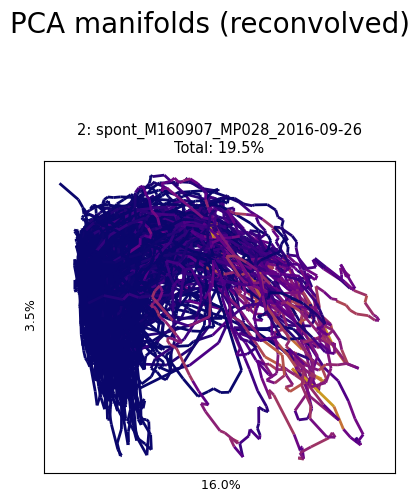

19.5%


In [8]:
plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filenames[plot_idx]}' for file_id in file_ids],
						  modes_manifold, [cb[['running_speed']] for cb in continuous_behaviors],
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PCA manifolds (reconvolved)', top_space=1,
						  save_path=None)

In [9]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

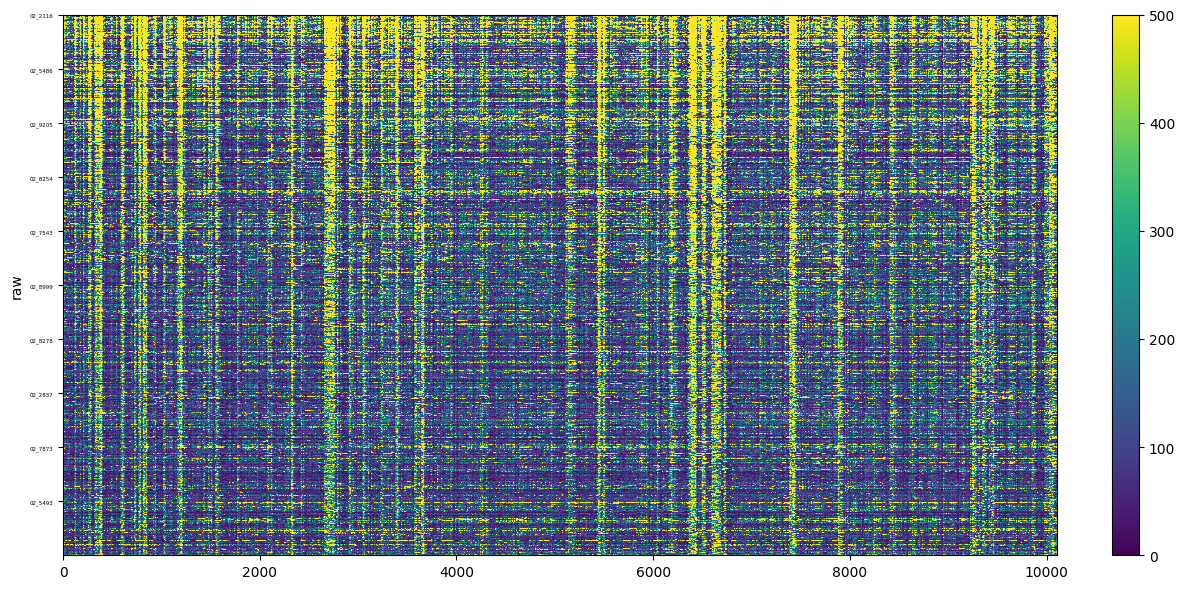

In [10]:
plot_utils.plot_heatmap_stack(traces_sorted[plot_idx].iloc[:, :1000],
							  None,
							  label_traces='raw', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')

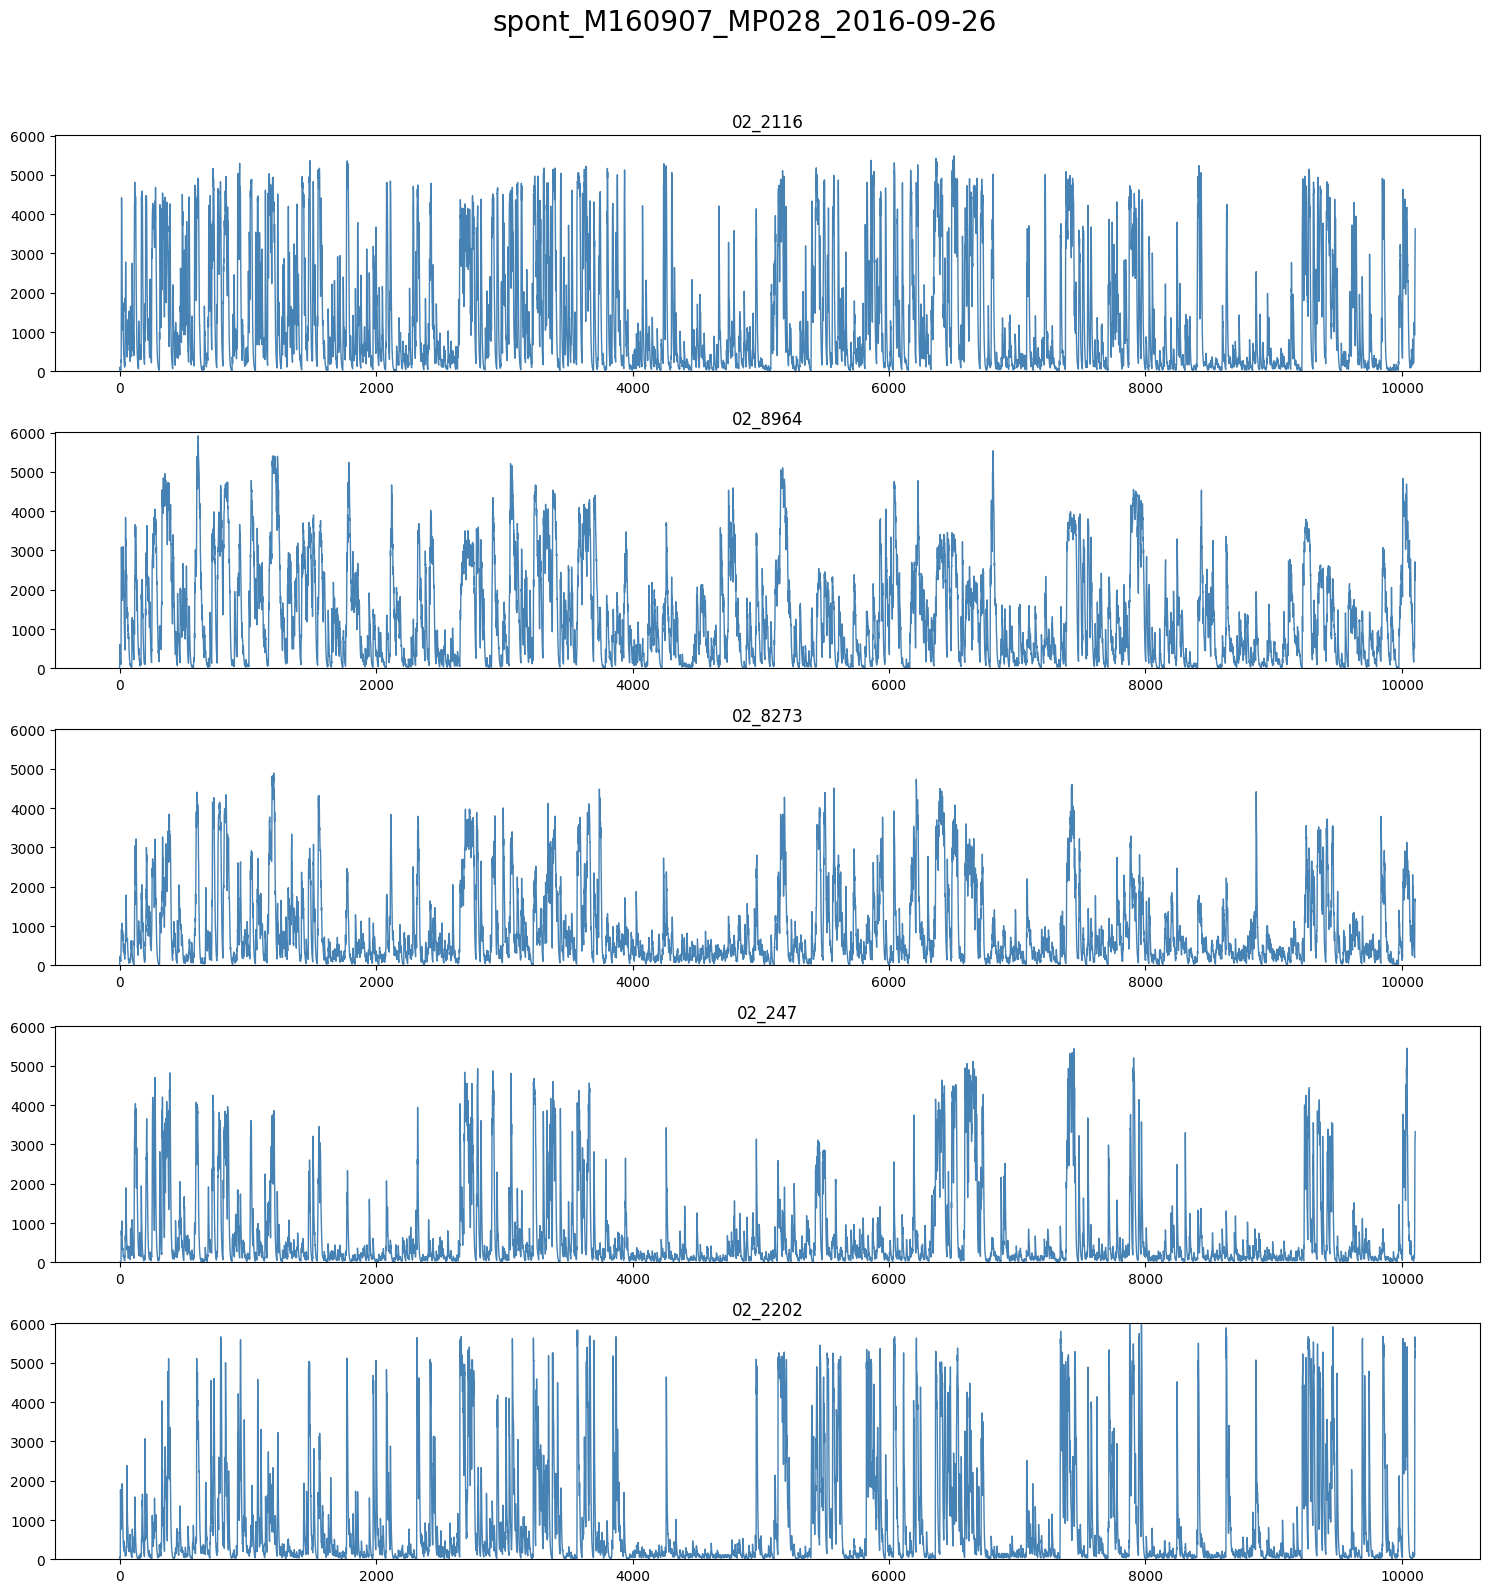

In [11]:
# max = 1000
max = traces_sorted[plot_idx].values.shape[0]
plot_utils.plot_traces(traces_sorted[plot_idx].iloc[:, :neurons_max],
					   None, None,
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

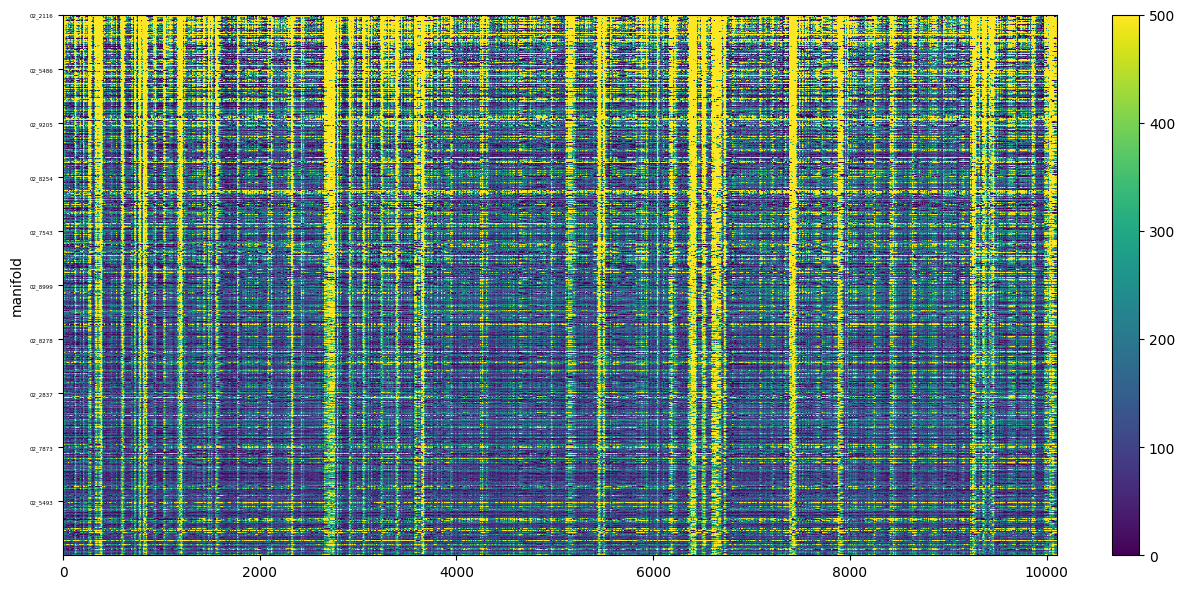

In [12]:
plot_utils.plot_heatmap_stack(traces_manifolds_sorted[plot_idx].iloc[:, :1000],
							  None,
							  label_traces='manifold', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')

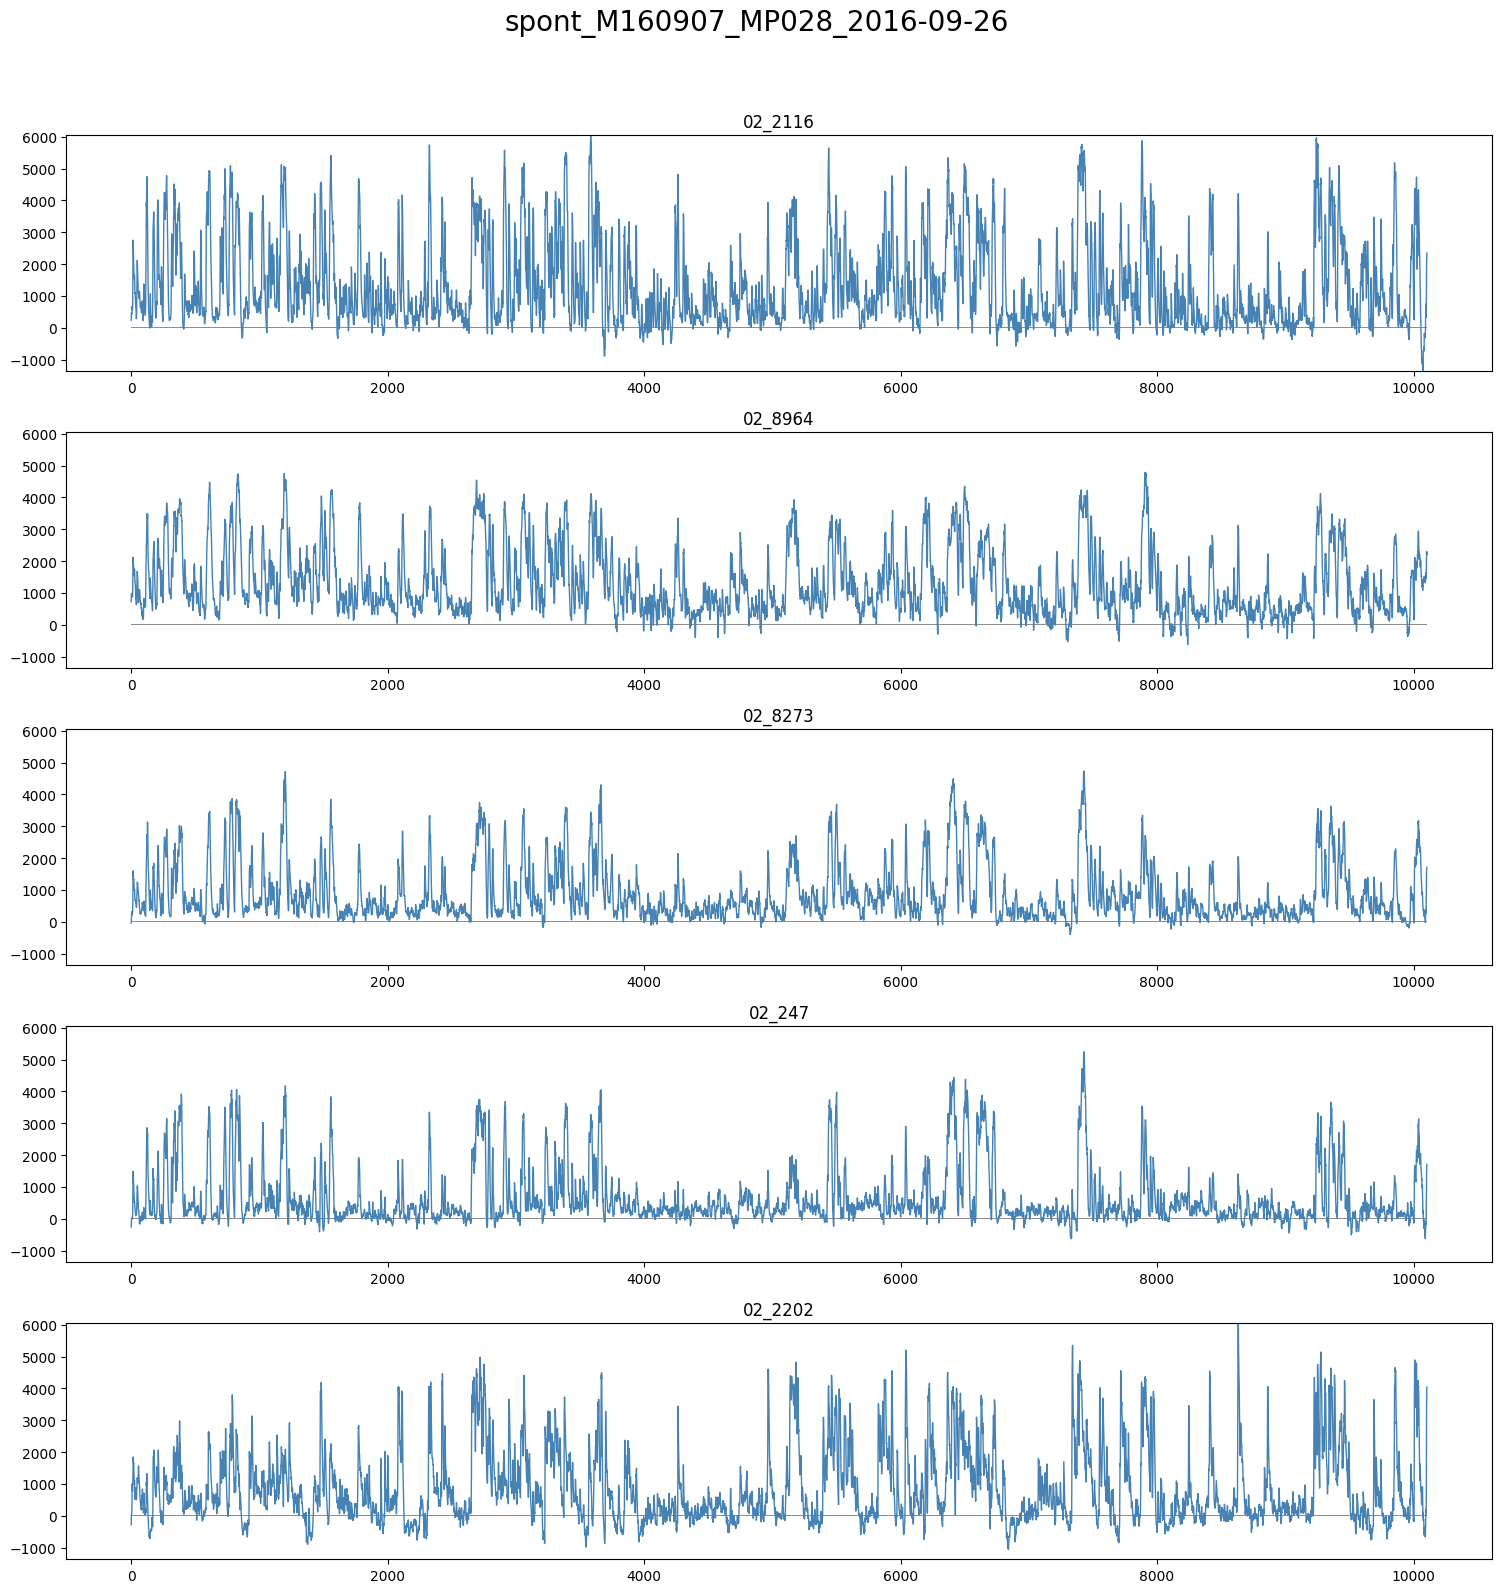

In [13]:
# max = 1000
max = traces_manifolds_sorted[plot_idx].values.shape[0]
plot_utils.plot_traces(traces_manifolds_sorted[plot_idx].iloc[:, :5],
					   None, None,
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

In [14]:
traces_residuals = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip(traces, recos_manifold)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

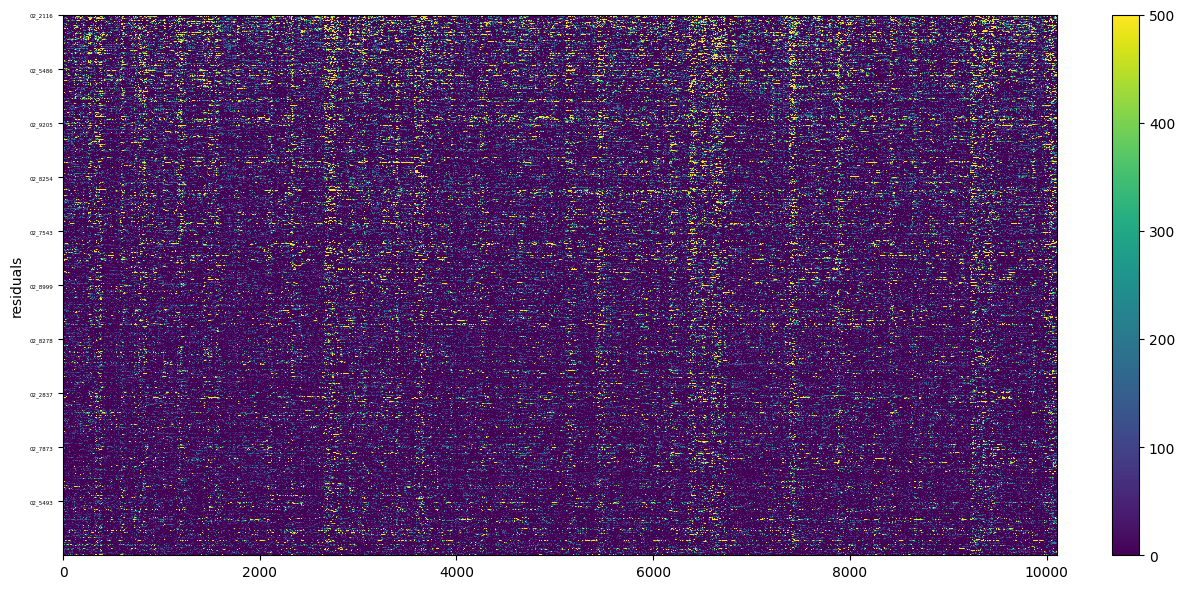

In [15]:
plot_utils.plot_heatmap_stack(traces_residuals_sorted_by_manifold[plot_idx].iloc[:, :1000],
							  None,
							  label_traces='residuals', label_behavior=None,
							  height_ratios=(0, 1),
							  zlimits_activity=(0, 500), cmap='viridis')

# regression

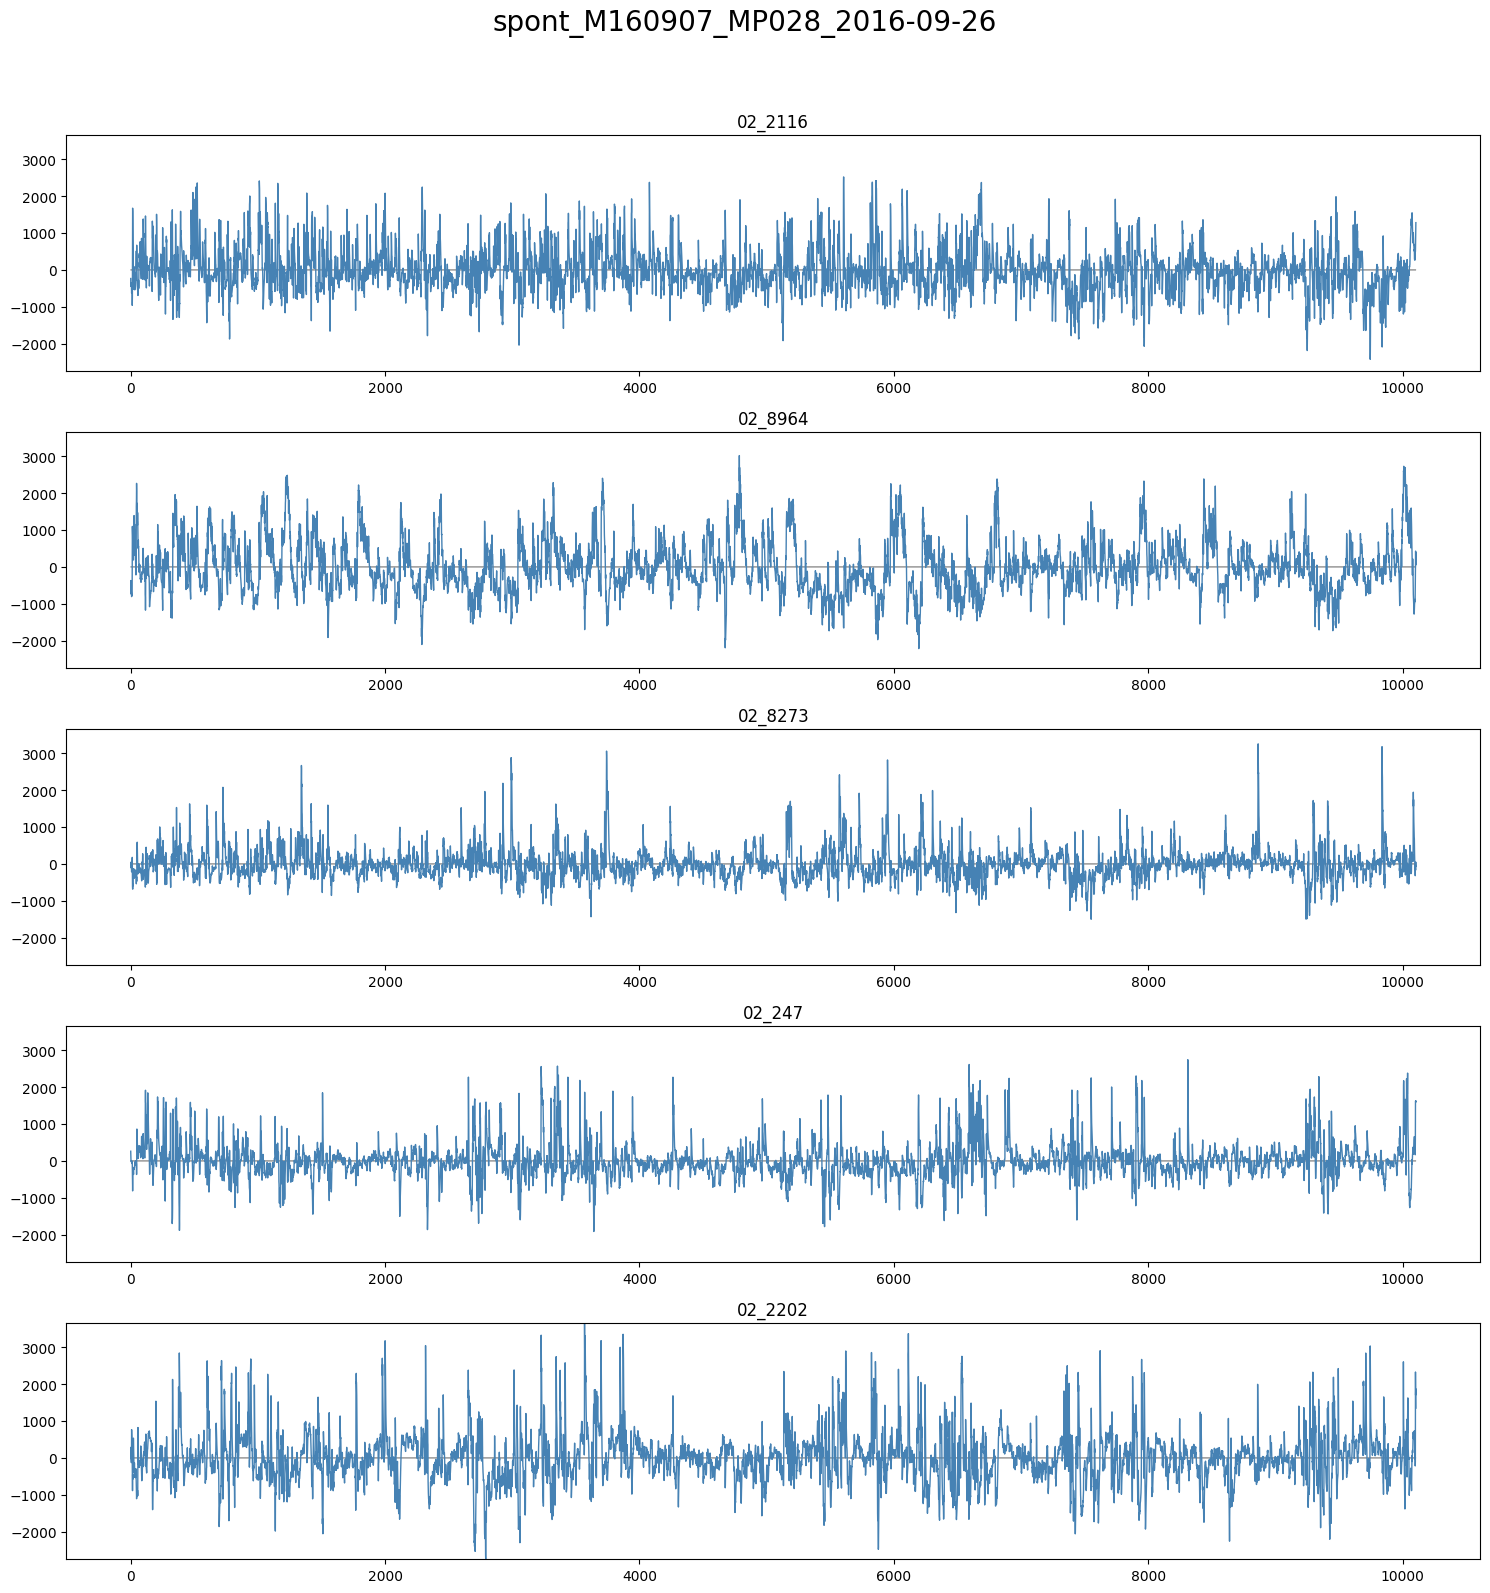

In [16]:
# max = 1000
max = traces_residuals_sorted_by_manifold[plot_idx].values.shape[0]
plot_utils.plot_traces(traces_residuals_sorted_by_manifold[plot_idx].iloc[:, :neurons_max],
					   None, None,
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

In [17]:
behavior = motion_pcs[plot_idx][0]
behavior_zs = pd.DataFrame(
	data=(behavior.values - behavior.values.mean(axis=0)) / np.where((behavior_std := np.std(behavior.values, axis=0)) == 0.0, 1.0, behavior_std),
	columns=behavior.columns
)

In [18]:
def r2_score_oos(y_eval, y_pred, baseline):
	ss_res = np.sum((y_eval - y_pred) ** 2, axis=0)
	ss_tot = np.sum((y_eval - baseline) ** 2, axis=0)
	return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)

In [19]:
trace = traces_residuals[plot_idx]

scaler = StandardScaler()
trace_zs = scaler.fit_transform(trace.values)

X_train, X_test, Y_train, Y_test = train_test_split(
	behavior.values, trace_zs, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, Y_train)

Y_test_pred = lr.predict(X_test)

r2 = r2_score_oos(Y_test, Y_test_pred, Y_train.mean(axis=0)).reshape(-1, 1).T
r2s = pd.DataFrame(data=r2, columns=trace.columns)

r2_mean = np.mean(r2_score_oos(Y_test, Y_test_pred, Y_train.mean(axis=0)))
mse = mean_squared_error(Y_test, Y_test_pred)

traces_residual_pred = pd.DataFrame(data=scaler.inverse_transform(lr.predict(behavior.values)), columns=trace.columns)

print('Mean R﷿﷿:\t', r2_mean)
print('MSE:\t\t', mse)

/tmp/ipykernel_173967/718207365.py:4: RuntimeWarning: invalid value encountered in divide
  return np.where(ss_tot > 0.0, 1.0 - ss_res / ss_tot, 0.0)


Mean R﷿﷿:	 0.12445491872461038
MSE:		 0.8795290912993425


In [20]:
r2_indices = np.argsort(r2s.values.reshape(-1,))[::-1]
print(r2s.iloc[:, r2_indices[:5]])

   02_5357   02_3869   02_1415   02_7546   02_6689
0  0.54942  0.526048  0.523499  0.518992  0.513353


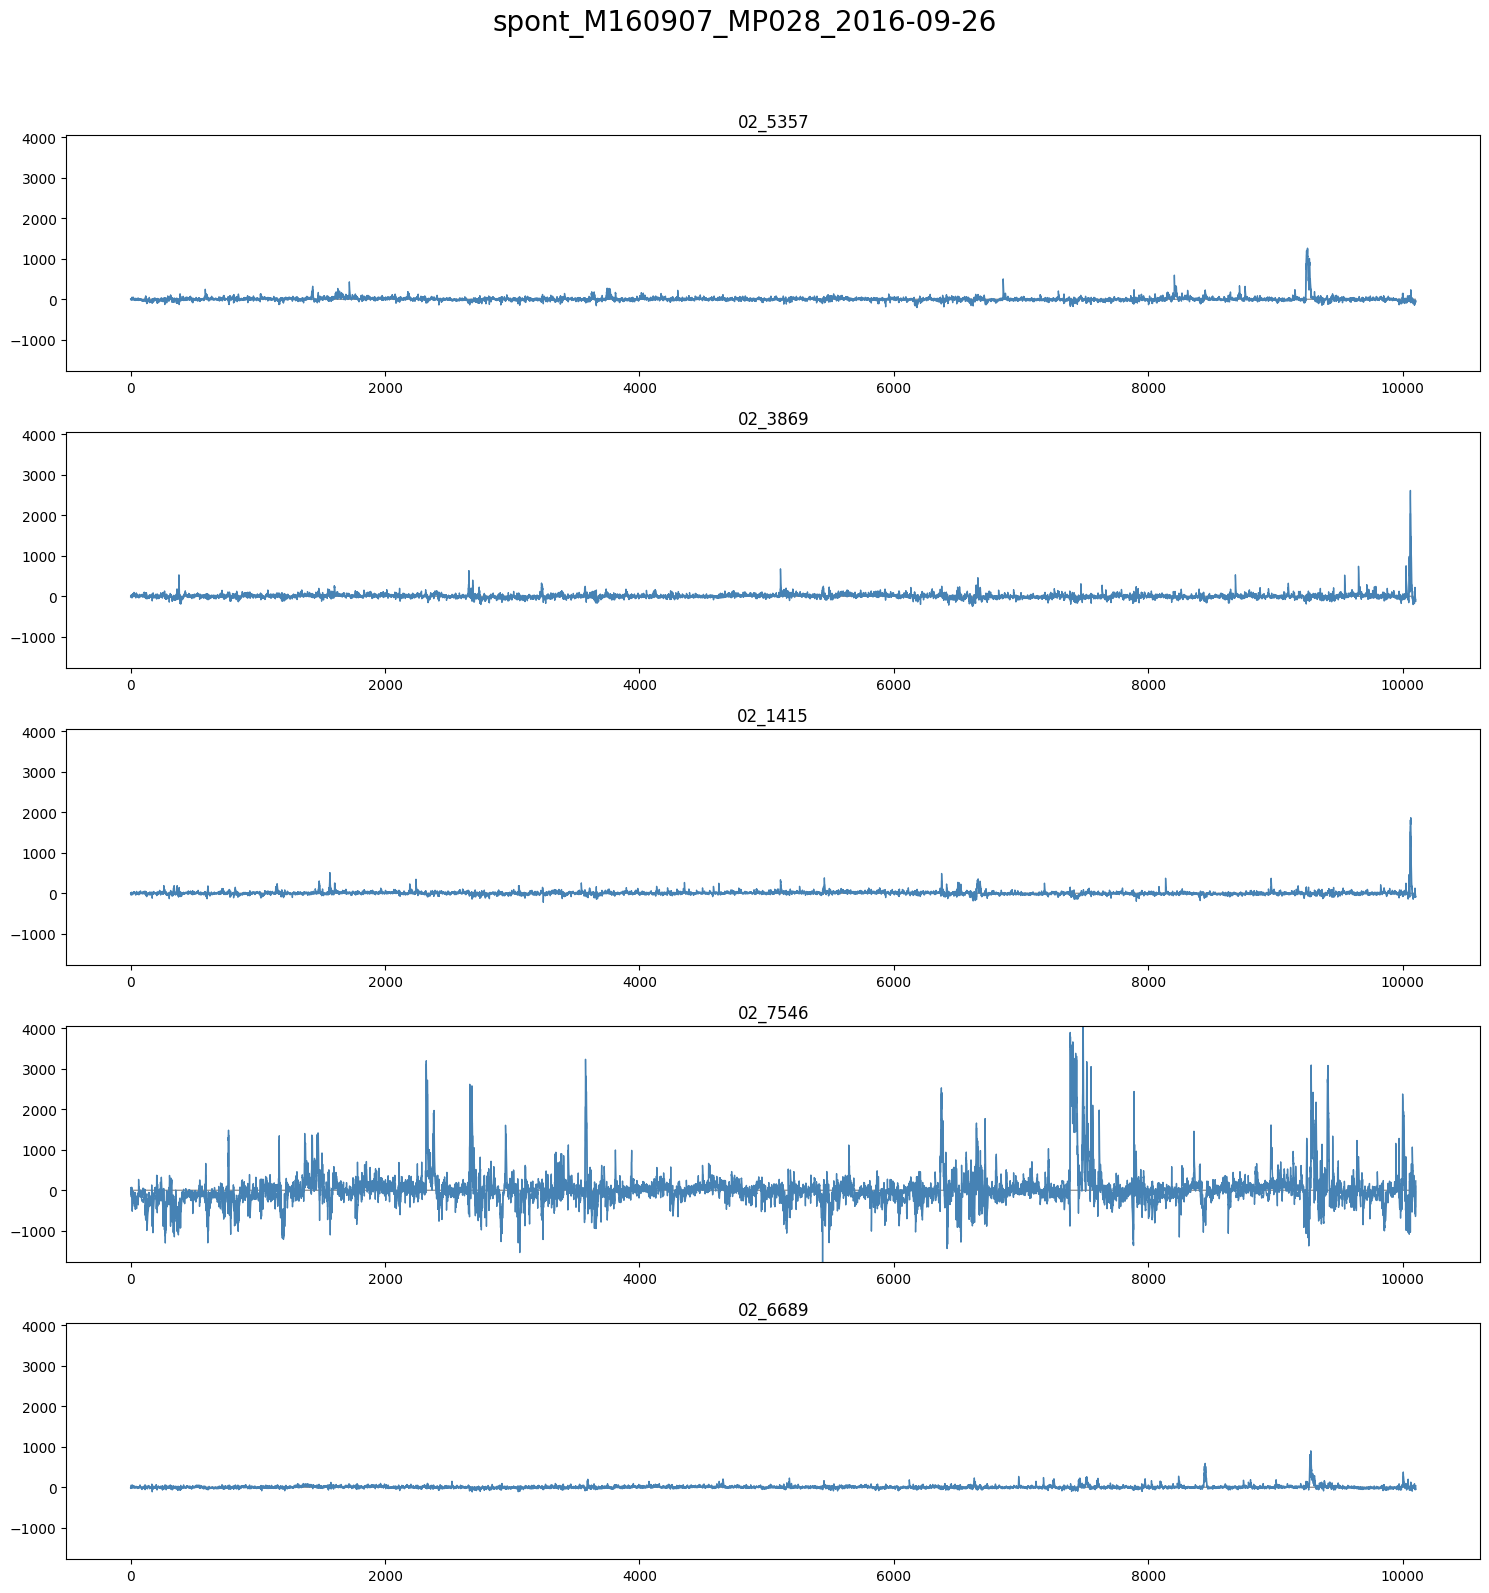

In [21]:
# max = 1000
max = traces_residuals[plot_idx].values.shape[0]

plot_utils.plot_traces([traces_residuals[plot_idx].iloc[:max, r2_indices[:5]],
					    traces_residual_pred.iloc[:max, r2_indices[:5]]],
					   None, None,
					   title=f'{filenames[plot_idx]}',
					   ylimits=None, plots_per_row=1, top_space=1)

# CCA comparison

In [ ]:
# # n_ccv = motion_pcs[plot_idx][0].values.shape[1]
# n_ccv = 16
#
# modes_concrete, modes_concrete_b = list(), list()
# recos_concrete, recos_concrete_b = list(), list()
# loads_cca_con, loads_cca_con_b = list(), list()
# vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data
#
# behavior = motion_pcs[plot_idx][0]
# behavior_zs = pd.DataFrame(
# 	data=(behavior.values - behavior.values.mean(axis=0)) / np.where((behavior_std := np.std(behavior.values, axis=0)) == 0.0, 1.0, behavior_std),
# 	columns=behavior.columns
# )
# trace = traces[plot_idx]
# trace_residual = traces_residuals[plot_idx]
#
# cca = CCA(n_components=n_ccv, scale=True)
#
# trace_residual_reduced, marker_reduced = cca.fit_transform(trace_residual.values, behavior_zs.values)
# trace_residual_reconstructed, marker_reconstructed = cca.inverse_transform(trace_residual_reduced, marker_reduced)
#
# modes_concrete = pd.DataFrame(data=trace_residual_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)])
# recos_concrete = pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns)
#
# modes_concrete_b = pd.DataFrame(data=marker_reduced, columns=[f'CV{i + 1}' for i in range(n_ccv)])
# recos_concrete_b = pd.DataFrame(data=marker_reconstructed, columns=behavior_zs.columns)
#
# loads_cca_con = cca.x_loadings_
# loads_cca_con_b = cca.y_loadings_
#
# var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace.values)
# var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual.values)
# vars_expl_con = [var_ratio]
# vars_expl_con_rs = [var_ratio_rs]

In [ ]:
# plot_utils.plot_manifolds([f'{str(plot_id)}: {filenames[plot_idx]}'] * 2,
# 						  modes_concrete, behavior_zs,
# 						  vars_expl_con[:], vars_expl_con_rs[:],
# 						  top_space=6.5)